# Reuse-Based PRRIP Results


## Libraries


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

## Server Workloads


In [3]:
server = pd.DataFrame({
    'LRU': [0.31536, 0.337624, 0.468506, 0.365451, 0.333307],
    'SRRIP': [0.315939, 0.347646, 0.469205, 0.365395, 0.333392],
    'PRRIP': [0.317769, 0.369233, 0.471733, 0.367428, 0.33578],
}, index=['Chirper', 'Tomcat', 'Kafka', 'TPC-C', 'Wikipedia'])

server.round(6)


,LRU,SRRIP,PRRIP
Chirper,0.315360,0.315939,0.317769
Tomcat,0.337624,0.347646,0.369233
Kafka,0.468506,0.469205,0.471733
TPC-C,0.365451,0.365395,0.367428
Wikipedia,0.333307,0.333392,0.335780


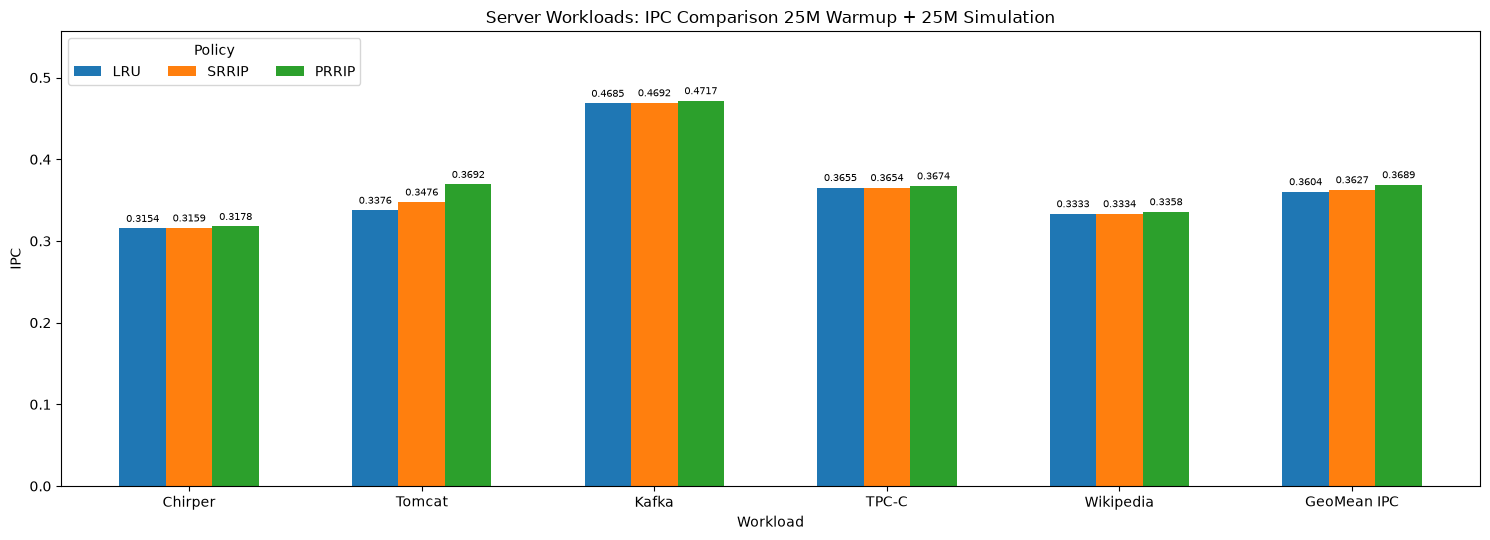

In [4]:
server_gm = server.prod() ** (1 / len(server))
server_plot = server.copy()
server_plot.loc["GeoMean IPC"] = server_gm

ax = server_plot.plot(kind="bar", figsize=(15, 5.5), width=0.6)

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.4f", padding=3, fontsize=7)

ax.set_title("Server Workloads: IPC Comparison 25M Warmup + 25M Simulation")
ax.set_xlabel("Workload")
ax.set_ylabel("IPC")
ax.set_ylim(0, server_plot.max().max() * 1.18)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Policy", loc="upper left", ncol=3)
plt.tight_layout()
plt.savefig("../results/prrip2_server_ipc.png", dpi=300)
plt.show()


## SPEC Benchmarks


In [5]:
spec = pd.DataFrame({
    'LRU': [0.22032, 0.320365, 0.496336, 0.252654, 0.557377, 0.578316],
    'SRRIP': [0.220988, 0.320032, 0.494313, 0.252687, 0.562065, 0.578813],
    'PRRIP': [0.225101, 0.320189, 0.492721, 0.252693, 0.79509, 0.582637],
}, index=['OMNeT++', 'MCF', 'LBM', 'GCC', 'Xalan', 'XZ'])

spec.round(6)


,LRU,SRRIP,PRRIP
OMNeT++,0.220320,0.220988,0.225101
MCF,0.320365,0.320032,0.320189
LBM,0.496336,0.494313,0.492721
GCC,0.252654,0.252687,0.252693
Xalan,0.557377,0.562065,0.795090
XZ,0.578316,0.578813,0.582637


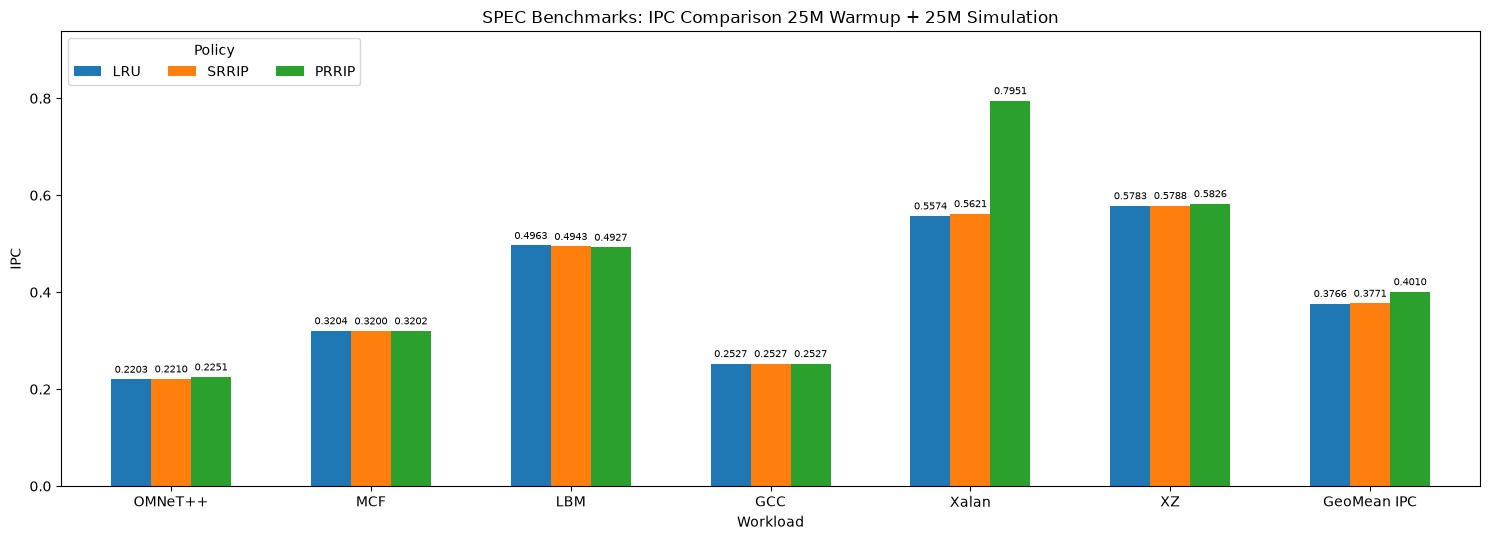

In [6]:
spec_gm = spec.prod() ** (1 / len(spec))
spec_plot = spec.copy()
spec_plot.loc["GeoMean IPC"] = spec_gm

ax = spec_plot.plot(kind="bar", figsize=(15, 5.5), width=0.6)

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.4f", padding=3, fontsize=7)

ax.set_title("SPEC Benchmarks: IPC Comparison 25M Warmup + 25M Simulation")
ax.set_xlabel("Workload")
ax.set_ylabel("IPC")
ax.set_ylim(0, spec_plot.max().max() * 1.18)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Policy", loc="upper left", ncol=3)
plt.tight_layout()
plt.savefig("../results/prrip2_spec_ipc.png", dpi=300)
plt.show()


## Geometric Mean IPC Gains


In [7]:
all_workloads = pd.concat([server, spec])
all_gm = all_workloads.prod() ** (1 / len(all_workloads))

gain = pd.DataFrame({
    "vs LRU (%)": [
        (server_gm["PRRIP"] / server_gm["LRU"] - 1) * 100,
        (spec_gm["PRRIP"] / spec_gm["LRU"] - 1) * 100,
        (all_gm["PRRIP"] / all_gm["LRU"] - 1) * 100
    ],
    "vs SRRIP (%)": [
        (server_gm["PRRIP"] / server_gm["SRRIP"] - 1) * 100,
        (spec_gm["PRRIP"] / spec_gm["SRRIP"] - 1) * 100,
        (all_gm["PRRIP"] / all_gm["SRRIP"] - 1) * 100
    ]
}, index=["Server", "SPEC", "All 11"])

gain.round(3)


,vs LRU (%),vs SRRIP (%)
Server,2.363,1.696
SPEC,6.475,6.346
All 11,4.585,4.206
